# Which key figures describe an LV grid, and which should we cluster on?

`pylovo-classify` draws a sample of postcode areas (PLZ), condenses every grid of the sample to one row of key figures
and clusters the grids on a few of them. This notebook shows the sample, the key figures and how the few are chosen.
The clusters follow in [02_clusters_and_representatives](02_clusters_and_representatives.ipynb).

**Needs:** a classification run (`pylovo-classify`, see [Classifying grids](https://pylovo.readthedocs.io/en/latest/user_guide/classification.html)), the `notebooks` extra and a
`.env` that points to the database (see `notebook_tutorials/README.md`). The notebook only reads. The stored outputs
show a classification of 501 Bavarian PLZ, drawn from LV version 1 of the pylovo results database.

In [1]:
# Parameters
classification_id = None  # None: CLASSIFICATION_VERSION of config_classification.yaml
version_id = None  # None: VERSION_ID of config_generation_lv.yaml
n_factors = None  # None: one factor per eigenvalue above 1, as pylovo-classify does

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

from pylovo.classification.clustering.get_parameters_for_clustering import factor_analysis_input, number_of_factors
from pylovo.classification.clustering.transform import transform_key_figures
from pylovo.classification.database_communication.database_communication import DatabaseCommunication
from pylovo.classification.sampling.sample import get_sample_set
from pylovo.database.database_client import DatabaseClient
from pylovo.plotting.classification import (
    REGIOSTAR7_NAMES,
    get_parameters_for_clustering,
    plot_correlation_matrix,
    plot_eigendecomposition,
    plot_factor_analysis,
    plot_key_figure_distributions,
    plot_sample_map,
    plot_samples_per_regiostarclass,
)

plt.rcParams["figure.dpi"] = 80  # moderate resolution of the stored figures
dc = DatabaseCommunication(classification_id, version_id)
print(f"Classification {dc.classification_id}, grids of version {dc.version_id}")

Database connection is constructed. 
Classification 2, grids of version 1


## Which postcode areas are in the sample?

Every RegioStaR 7 class gets PLZ in proportion to its population; within a class the drawn PLZ follow the distribution
of the population density.

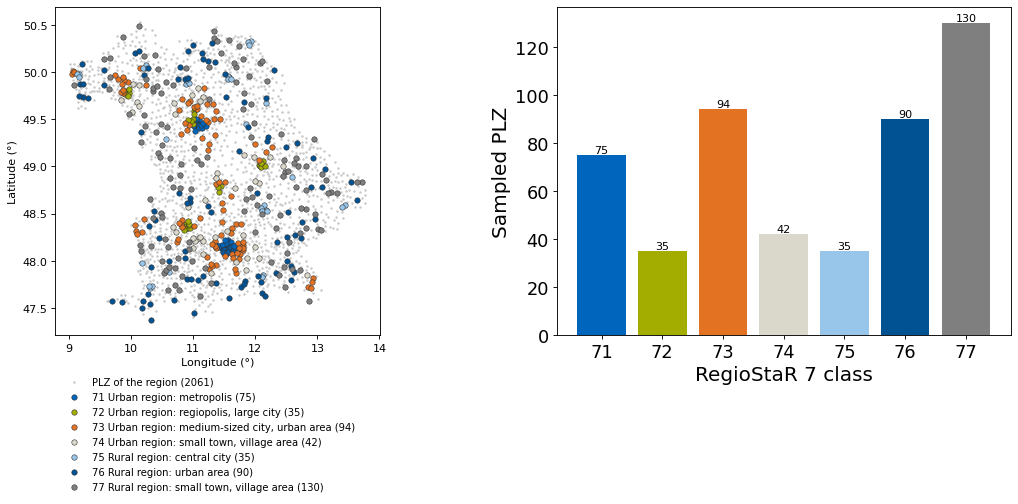

In [3]:
samples = get_sample_set(dc.classification_id)
with DatabaseClient() as client:
    register = client.get_municipal_register().sort_values(["plz", "ags"]).drop_duplicates("plz")  # as the draw
region = register[register["fed_state"].isin(samples["fed_state"])].dropna(subset=["regio7"])
fig, (map_ax, bar_ax) = plt.subplots(1, 2, figsize=(14, 6.5), width_ratios=[1.2, 1])
plot_sample_map(samples, region, ax=map_ax)
plot_samples_per_regiostarclass(samples, ax=bar_ax)
fig.tight_layout()

In [4]:
region_classes, sample_classes = region["regio7"].astype(int), samples["regio7"].astype(int)
pd.DataFrame({
    "class": REGIOSTAR7_NAMES,
    "population share (%)": (100 * region.groupby(region_classes)["pop"].sum() / region["pop"].sum()).round(1),
    "PLZ in the region": region_classes.value_counts(),
    "PLZ sampled": sample_classes.value_counts(),
}).rename_axis("RegioStaR 7")

,class,population share (%),PLZ in the region,PLZ sampled
RegioStaR 7,,,,
71,Urban region: metropolis,14.9,104,75
72,"Urban region: regiopolis, large city",7.1,43,35
73,"Urban region: medium-sized city, urban area",18.8,219,94
74,"Urban region: small town, village area",8.3,286,42
75,Rural region: central city,6.9,38,35
76,Rural region: urban area,17.9,259,90
77,"Rural region: small town, village area",26.0,1112,130


The grey points are all PLZ of the region, the coloured ones the sample. The number of sampled PLZ follows the
population share of a class, not its number of PLZ: the many small PLZ of the rural class 77 are drawn less often
than the PLZ of the cities. Details: [Step 1: sample set](https://pylovo.readthedocs.io/en/latest/user_guide/classification.html#step-1-sample-set).

## Which key figures describe a grid?

pylovo computes one row of key figures per grid. The factor analysis starts from these 15; the other columns are
identifiers or excluded from the classification (`EXCLUDED_COLUMNS` of step 6a). A feeder is a cable that leaves the
station towards at least two buildings, as in the structural metrics of the validation. The per-feeder figures count
the buildings behind the feeders and are 0 for a grid without a feeder.

| Key figure | Meaning |
| --- | --- |
| `no_branches` | Feeders leaving the station |
| `no_branch_ends` | Ends of the shared cable network (more ends: more branching) |
| `no_house_connections` | Buildings (consumer buses) |
| `no_house_connections_per_branch` | Buildings per feeder |
| `no_households` | Households |
| `no_household_equ_per_branch` | Household equivalents (installed power / `PEAK_LOAD_HOUSEHOLD`) per feeder |
| `max_household_equ_of_a_branch` | Household equivalents of the largest feeder |
| `transformer_mva` | Rating of the transformer station (MVA) |
| `max_trafo_dis`, `avg_trafo_dis` | Longest and mean cable path from the station to a building (km) |
| `cable_length_km` | Installed cable length (km) |
| `cable_len_per_house` | Cable length per building (km) |
| `max_route_resistance_ohm` | Highest cable resistance from the station to a building (Ω) |
| `vsw_per_branch` | Path resistance weighted with the household equivalents (VSW) per feeder, a proxy of the voltage drop |
| `max_vsw_of_a_branch` | The VSW of the feeder with the largest value |

In [5]:
key_figures = dc.get_clustering_parameters_for_classification_version()
choices = dc.get_classification_choices()  # what the run stored, among it the transform
candidates = factor_analysis_input(key_figures)
transformed = transform_key_figures(candidates, choices["transform"])  # as step 6a
print(f"{len(key_figures)} grids in {key_figures['plz'].nunique()} PLZ, {candidates.shape[1]} candidate key figures, "
      f"transform {choices['transform']}")
candidates.describe().T.round(3)

26049 grids in 501 PLZ, 15 candidate key figures, transform yeo-johnson


,count,mean,std,min,25%,50%,75%,max
no_branches,26049.0,2.635,1.409,0.000,2.000,3.000,3.000,18.000
no_house_connections,26049.0,42.261,44.371,1.000,11.000,25.000,59.000,324.000
no_house_connections_per_branch,26049.0,13.353,14.003,0.000,4.250,8.750,17.600,204.000
no_households,26049.0,99.909,92.706,0.000,19.000,73.000,161.000,631.000
no_household_equ_per_branch,26049.0,34.906,31.872,0.000,10.974,24.986,51.128,287.139
max_household_equ_of_a_branch,26049.0,54.349,49.075,0.000,15.000,39.535,83.000,326.000
transformer_mva,26049.0,0.440,0.142,0.250,0.400,0.400,0.630,1.260
max_trafo_dis,26049.0,0.370,0.266,0.001,0.177,0.307,0.484,2.165
avg_trafo_dis,26049.0,0.166,0.112,0.001,0.088,0.143,0.215,1.463
cable_length_km,26049.0,1.746,1.708,0.001,0.572,1.234,2.453,83.858


Grids that the filters of the classification leave out are not in the table, by default those with a path longer than
2.5 km, a building with more than 150 households, a voltage violation or a power flow that did not converge ([Steps 4 and 5](https://pylovo.readthedocs.io/en/latest/user_guide/classification.html#steps-4-and-5-key-figures-and-filter)).
All columns: [Per-grid key figures](https://pylovo.readthedocs.io/en/latest/user_guide/analysing_grids.html#per-grid-key-figures-clustering-parameters).

## How are the key figures distributed?

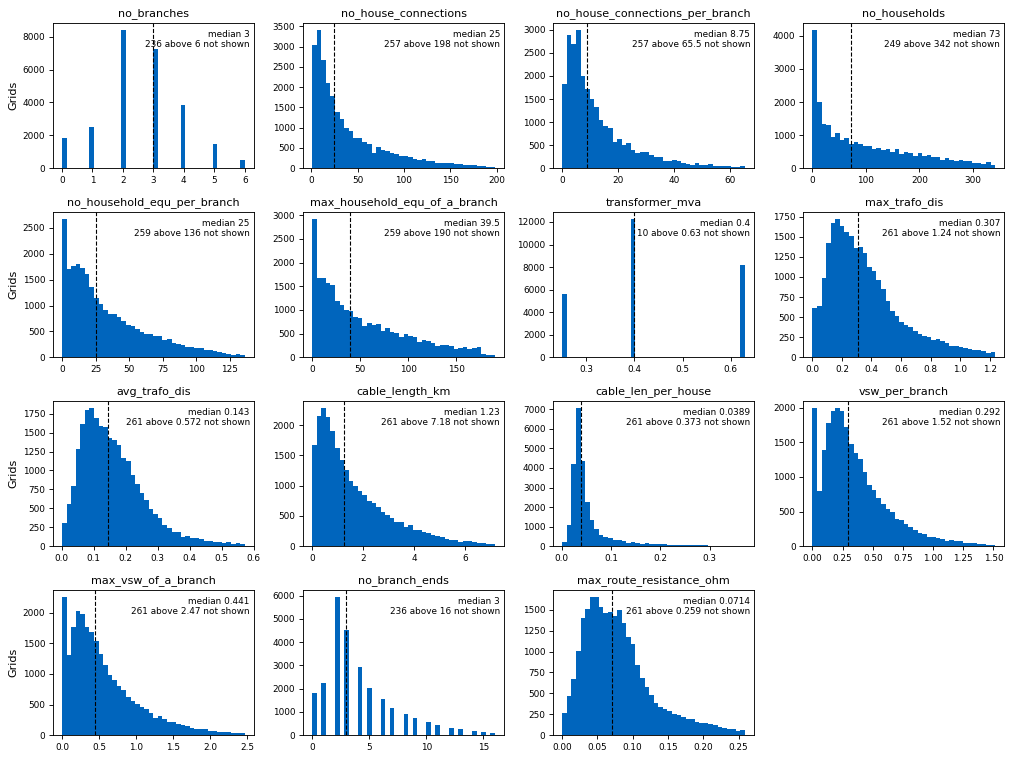

In [6]:
fig = plot_key_figure_distributions(candidates)

Most key figures are skewed to the right: many small grids, few large ones. Here the medians are 25 buildings,
73 households, 1.2 km of cable and three feeders per grid, and a quarter of the grids have fewer than 19 households.
Feeders and transformer rating take a few values only (250, 400 and 630 kVA). Before the factor analysis and the
clustering, the classification transforms every key figure (Yeo-Johnson, `TRANSFORM`) so that each one is close to
symmetric and the long tails no longer pull on the cluster centres. The figures below use the transformed values.

## Which key figures say the same?

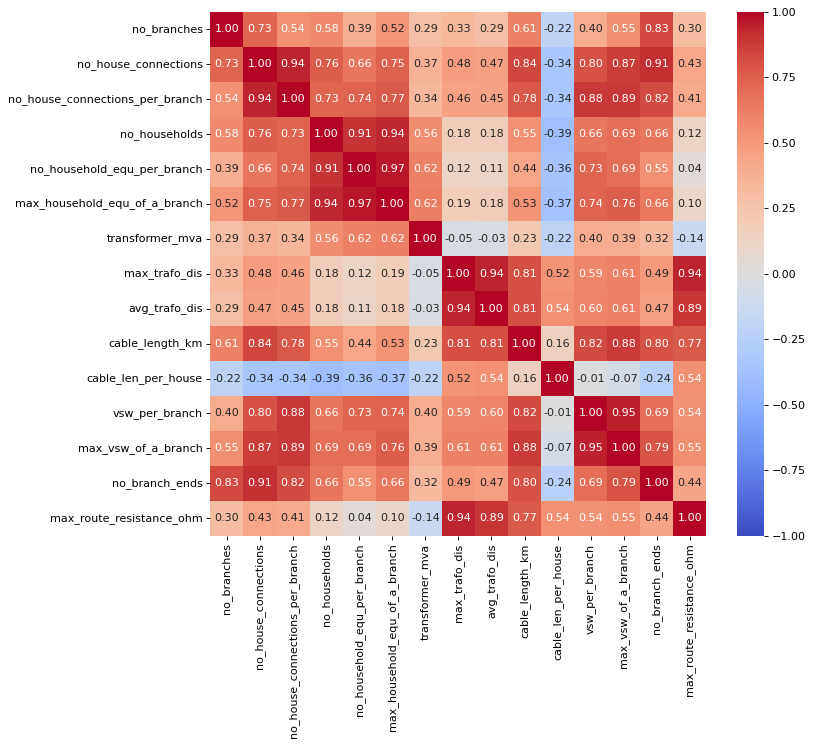

In [7]:
fig = plot_correlation_matrix(transformed.corr(), figsize=(10, 8.5))

Red blocks are key figures that rise together. Three blocks stand out: the size of the grid, with the buildings,
the cable length, the branch ends and the VSW (0.8 to 0.94), the households with the household equivalents per feeder
and of the largest feeder (0.91 to 0.97), and the distance from the station, with the two path lengths and the route
resistance (0.89 to 0.94). The cable per building correlates with none of them above 0.55. Clustering on all 15 key
figures would count the same property several times, so the factor analysis keeps one key figure per block.

## How many independent factors are there?

`pylovo-classify` keeps one factor per eigenvalue of the correlation matrix above 1 (Kaiser criterion).

3 factors


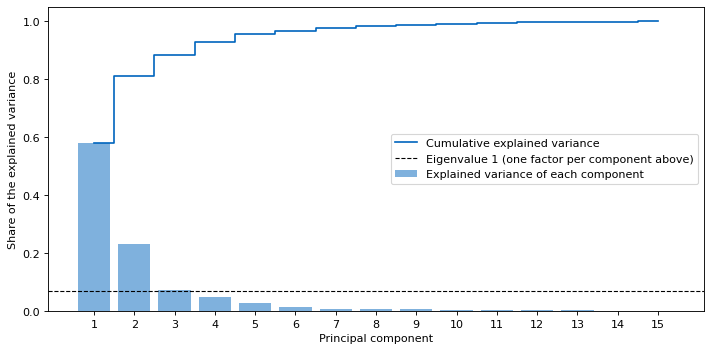

In [8]:
n = number_of_factors(transformed) if n_factors is None else n_factors
print(f"{n} factors")
fig = plot_eigendecomposition(transformed, figsize=(9, 4.5))

Each bar is a principal component. Its share of the variance is its eigenvalue divided by the number of key
figures, so the bars above the dashed line are the factors: three here, the third just above the line (eigenvalue
1.09). The step line shows that the three carry 88 % of the variance together.

## Which key figure stands for each factor?

A factor analysis with varimax rotation makes every factor load on a few key figures. For every factor
`pylovo-classify` takes the key figure with the largest absolute loading.

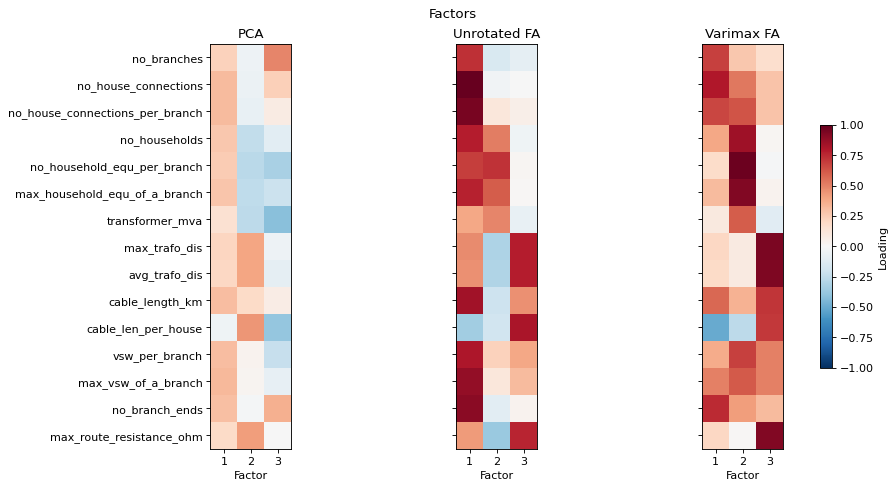

In [9]:
fig = plot_factor_analysis(transformed, n_comps=n, figsize=(11, 6))

Red is a positive, blue a negative loading. Without rotation (middle) the first factor loads on almost every key
figure. The varimax rotation (right) gives every factor a few strong loadings, which is why the selection uses
it. The three factors are the size of the grid (buildings, branch ends, cable length), the household equivalents per
feeder and the distance from the station. PCA (left) for comparison.

In [10]:
proposed = get_parameters_for_clustering(transformed, n_comps=n)  # prints one key figure per factor
choices

no_house_connections
no_household_equ_per_branch
max_trafo_dis


{'list_of_clustering_parameters': ['no_house_connections',
  'no_household_equ_per_branch',
  'max_trafo_dis'],
 'n_clusters_kmeans': 4,
 'n_clusters_gmm': 6,
 'additional_filtering': False,
 'transform': 'yeo-johnson',
 'exclude_infeasible': True}

Here the proposal equals the three key figures stored with the classification, the automatic choice of
`pylovo-classify`: one per factor. Two choices are close: `max_trafo_dis` leads `avg_trafo_dis` by a loading of
0.004, and the third eigenvalue lies just above 1. The selection report of the run (`log/selection_report_<id>.md`)
shows that all 100 PLZ resamples still keep three factors and pick the same three key figures. A manual run
(`pylovo-classify --manual --parameters ...`) can overrule them.
Details: [Step 6a: clustering parameters](https://pylovo.readthedocs.io/en/latest/user_guide/classification.html#step-6a-clustering-parameters).

## Next

[02_clusters_and_representatives](02_clusters_and_representatives.ipynb) clusters the grids on these key figures and
shows the representative grid of every cluster.